# B5 — Integrasi: Rangkaian Praproses SIMUTEH

Evaluasi Praktikum P1–P4 Computer Vision
SIMUTEH — Klasifikasi Kualitas Daun Teh

# 5.2 Evaluasi Kuantitatif

In [2]:
# Evaluasi Kuantitatif Rangkaian Praproses
from praproses import praproses, simpan_param

# Parameter praproses
param = {
    "lebar": 640,
    "gamma": 1.0,
    "clahe_clip": 2.0,
    "clahe_tile": 8,
    "penapis": "median",
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0
}

# Simpan parameter ke JSON
simpan_param(param, os.path.join(HASIL_DIR, "param_praproses.json"))

# Kanal BGR: 0 = B, 1 = G, 2 = R
# Sesuaikan dengan kanal terbaik dari hasil B2
KANAL = 2

label = pd.read_csv(os.path.join(DATA_DIR, "label.csv"))

baris = []

# Menguji seluruh 40 citra berbercak
for _, d in label[label.kelas != "sehat"].iterrows():

    nm = d["nama_file"]

    img = cv2.imread(os.path.join(DATA_DIR, "citra", nm))
    md = cv2.imread(os.path.join(DATA_DIR, "mask_daun", nm), 0)
    mb = cv2.imread(os.path.join(DATA_DIR, "mask_bercak", nm), 0)

    if img is None or md is None or mb is None:
        print("Citra atau mask tidak ditemukan:", nm)
        continue

    # Proses praproses
    out = praproses(img, param)

    # Sesuaikan ukuran mask dengan hasil praproses
    ukuran = (out.shape[1], out.shape[0])
    md_out = cv2.resize(md, ukuran, interpolation=cv2.INTER_NEAREST)
    mb_out = cv2.resize(mb, ukuran, interpolation=cv2.INTER_NEAREST)

    # Hitung KB sebelum dan sesudah
    kb_sebelum = kontras_bercak(img[:, :, KANAL], md, mb)
    kb_sesudah = kontras_bercak(out[:, :, KANAL], md_out, mb_out)

    baris.append([
        d["kondisi_cahaya"],
        nm,
        kb_sebelum,
        kb_sesudah
    ])

evaluasi = pd.DataFrame(
    baris,
    columns=["kondisi", "nama_file", "KB_sebelum", "KB_sesudah"]
)

# Rata-rata KB berdasarkan kondisi cahaya
ringkasan = evaluasi.groupby("kondisi")[
    ["KB_sebelum", "KB_sesudah"]
].mean()

ringkasan["Perubahan (%)"] = (
    (ringkasan["KB_sesudah"] - ringkasan["KB_sebelum"])
    / ringkasan["KB_sebelum"] * 100
)

print("HASIL EVALUASI RANGKAIAN PRAPROSES")
display(ringkasan.round(2))

print("Jumlah citra yang berhasil diuji:", len(evaluasi))

# Simpan hasil evaluasi
evaluasi.to_csv(
    os.path.join(HASIL_DIR, "b5_evaluasi_praproses.csv"),
    index=False
)

ringkasan.round(2).to_csv(
    os.path.join(HASIL_DIR, "b5_tabel12.csv")
)

ModuleNotFoundError: No module named 'praproses'

# 5.3 Uji Bercak Palsu pada Kelas Sehat

In [ ]:
# Uji Bercak Palsu pada Kelas Sehat
baris_sehat = []

# Mengambil 20 citra kelas sehat
data_sehat = label[label["kelas"] == "sehat"].head(20)

for _, d in data_sehat.iterrows():

    nm = d["nama_file"]

    img = cv2.imread(os.path.join(DATA_DIR, "citra", nm))
    md = cv2.imread(os.path.join(DATA_DIR, "mask_daun", nm), 0)

    out = praproses(img, param)

    # Sesuaikan mask dengan ukuran hasil praproses
    md_out = cv2.resize(
        md,
        (out.shape[1], out.shape[0]),
        interpolation=cv2.INTER_NEAREST
    )

    # Simpangan baku kanal terpilih pada area daun
    std_sebelum = img[:, :, KANAL][md > 0].std()
    std_sesudah = out[:, :, KANAL][md_out > 0].std()

    baris_sehat.append([
        nm,
        d["kondisi_cahaya"],
        std_sebelum,
        std_sesudah
    ])

hasil_sehat = pd.DataFrame(
    baris_sehat,
    columns=["nama_file", "kondisi", "std_sebelum", "std_sesudah"]
)

print("HASIL UJI 20 CITRA KELAS SEHAT")
display(
    hasil_sehat.groupby("kondisi")[
        ["std_sebelum", "std_sesudah"]
    ].mean().round(2)
)

print("Jumlah citra:", len(hasil_sehat))

# Panel sebelum dan sesudah untuk satu citra setiap kondisi
kondisi_unik = hasil_sehat["kondisi"].unique()

plt.figure(figsize=(12, 4 * len(kondisi_unik)))

for i, kondisi in enumerate(kondisi_unik):

    nm = hasil_sehat[
        hasil_sehat["kondisi"] == kondisi
    ].iloc[0]["nama_file"]

    img = cv2.imread(os.path.join(DATA_DIR, "citra", nm))
    out = praproses(img, param)

    plt.subplot(len(kondisi_unik), 2, 2*i + 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(f"{kondisi} - Sebelum")
    plt.axis("off")

    plt.subplot(len(kondisi_unik), 2, 2*i + 2)
    plt.imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))
    plt.title(f"{kondisi} - Sesudah")
    plt.axis("off")

plt.tight_layout()
plt.show()

hasil_sehat.to_csv(
    os.path.join(HASIL_DIR, "b5_uji_bercak_palsu.csv"),
    index=False
)

NameError: name 'label' is not defined

# 5.4 Justifikasi

In [ ]:
# B5.4 - Tabel 13: Justifikasi Parameter Final

tabel13 = pd.DataFrame([
    [
        "Resize",
        "640 piksel",
        "Menyeragamkan ukuran citra agar proses praproses memiliki dimensi yang konsisten.",
        "Ukuran terlalu kecil dapat menghilangkan detail bercak."
    ],
    [
        "Gamma",
        "1.0",
        "Mempertahankan intensitas asli citra tanpa perubahan gamma.",
        "Gamma terlalu tinggi atau rendah dapat membuat citra terlalu terang atau gelap."
    ],
    [
        "CLAHE clip limit",
        "2.0",
        "Meningkatkan kontras lokal agar bercak lebih terlihat.",
        "Nilai terlalu tinggi dapat memperkuat noise dan detail yang tidak diperlukan."
    ],
    [
        "CLAHE tile",
        "8",
        "Membagi citra menjadi area lokal untuk pemerataan kontras.",
        "Pembagian area yang tidak tepat dapat menghasilkan kontras yang tidak merata."
    ],
    [
        "Penapis",
        "Median",
        "Dipilih untuk mereduksi noise sekaligus mempertahankan tepi objek.",
        "Kernel terlalu besar dapat menghilangkan detail bercak kecil."
    ],
    [
        "Kernel",
        "3",
        "Ukuran kecil dipilih agar pengurangan noise tidak terlalu menghilangkan detail.",
        "Kernel terlalu besar dapat membuat bercak menjadi kabur atau hilang."
    ],
    [
        "Sigma",
        "1.0",
        "Menjadi nilai parameter standar untuk proses Gaussian apabila penapis tersebut digunakan.",
        "Nilai sigma terlalu besar dapat menghaluskan citra secara berlebihan."
    ],
    [
        "Ketajaman (tajam_k)",
        "0.0",
        "Tidak menggunakan penajaman tambahan agar tidak memperkuat noise atau menghasilkan bercak palsu.",
        "Penajaman berlebihan dapat membuat noise terlihat seperti bercak."
    ]
], columns=[
    "Parameter",
    "Nilai Final",
    "Alasan dan Bukti",
    "Risiko Jika Tidak Tepat"
])

display(tabel13)
tabel13.to_csv(
    os.path.join(HASIL_DIR, "b5_tabel13_justifikasi.csv"),
    index=False
)

,Parameter,Nilai Final,Alasan dan Bukti,Risiko Jika Tidak Tepat
0,Resize,640 piksel,Menyeragamkan ukuran citra agar proses prapros...,Ukuran terlalu kecil dapat menghilangkan detai...
1,Gamma,1.0,Mempertahankan intensitas asli citra tanpa per...,Gamma terlalu tinggi atau rendah dapat membuat...
2,CLAHE clip limit,2.0,Meningkatkan kontras lokal agar bercak lebih t...,Nilai terlalu tinggi dapat memperkuat noise da...
3,CLAHE tile,8,Membagi citra menjadi area lokal untuk pemerat...,Pembagian area yang tidak tepat dapat menghasi...
4,Penapis,Median,Dipilih untuk mereduksi noise sekaligus memper...,Kernel terlalu besar dapat menghilangkan detai...
5,Kernel,3,Ukuran kecil dipilih agar pengurangan noise ti...,Kernel terlalu besar dapat membuat bercak menj...
6,Sigma,1.0,Menjadi nilai parameter standar untuk proses G...,Nilai sigma terlalu besar dapat menghaluskan c...
7,Ketajaman (tajam_k),0.0,Tidak menggunakan penajaman tambahan agar tida...,Penajaman berlebihan dapat membuat noise terli...


# 5.4 Diagram Pipeline

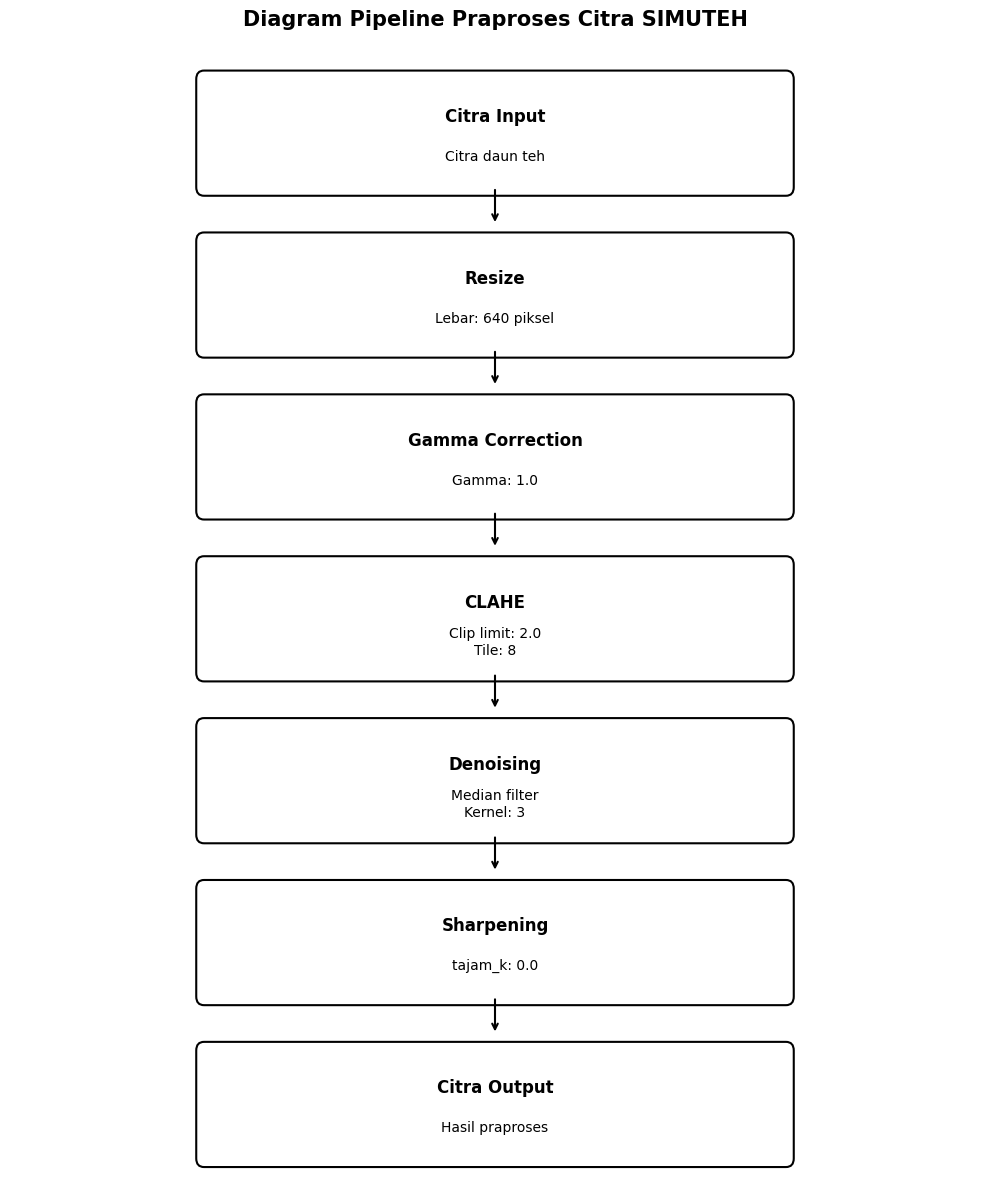

In [ ]:
# B5.4 - Diagram Pipeline Praproses SIMUTEH

from matplotlib.patches import FancyBboxPatch

tahapan = [
    ("Citra Input", "Citra daun teh"),
    ("Resize", "Lebar: 640 piksel"),
    ("Gamma Correction", "Gamma: 1.0"),
    ("CLAHE", "Clip limit: 2.0\nTile: 8"),
    ("Denoising", "Median filter\nKernel: 3"),
    ("Sharpening", "tajam_k: 0.0"),
    ("Citra Output", "Hasil praproses")
]

fig, ax = plt.subplots(figsize=(10, 12))
ax.set_xlim(0, 10)
ax.set_ylim(0, len(tahapan) * 1.5)
ax.axis("off")

for i, (judul, detail) in enumerate(tahapan):
    y = len(tahapan) * 1.5 - (i + 1) * 1.5 + 0.2

    kotak = FancyBboxPatch(
        (2, y), 6, 1.0,
        boxstyle="round,pad=0.08",
        edgecolor="black",
        facecolor="white",
        linewidth=1.5
    )
    ax.add_patch(kotak)

    ax.text(
        5, y + 0.65, judul,
        ha="center", va="center",
        fontsize=12, fontweight="bold"
    )
    ax.text(
        5, y + 0.28, detail,
        ha="center", va="center",
        fontsize=10
    )

    if i < len(tahapan) - 1:
        ax.annotate(
            "",
            xy=(5, y - 0.35),
            xytext=(5, y),
            arrowprops=dict(arrowstyle="->", linewidth=1.5)
        )

ax.set_title(
    "Diagram Pipeline Praproses Citra SIMUTEH",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.tight_layout()
plt.savefig(
    os.path.join(HASIL_DIR, "b5_diagram_pipeline.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()